##### UPSC ESSAY EVALUATOR --- USING PARALLEL CAHIN CONCEPTS

In [12]:
from langgraph.graph import StateGraph,START,END
from pydantic import BaseModel,Field
from typing import TypedDict,Annotated,List
import operator

In [13]:
## defining the evaluation schema
class EvaluationSchema(BaseModel):
    feedback:str=Field(description="Detailed textual feedback for the specific aspect.")
    score:int=Field(description="score between 0 and 10(inclusive)",ge=0,le=10)

## defining the state memory
class UPSCstate(TypedDict):
    essay:str
    language_feedback:str
    depth_feedback:str
    clarity_feedback:str
    overall_feedback:str

    invidual_score:Annotated[List[int],operator.add]
    average_score:float

    

In [14]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import prompt
llm_raw=ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")
llm=llm_raw.with_structured_output(EvaluationSchema)

In [ ]:
## defining the function to retrieve the evaluations

def evaluate_language(state:UPSCstate)->dict:
    prompt=f"Evaluate the LANGUAGE quality of the following essay:\n\n{state['essay']}"
    res:EvaluationSchema=llm.invoke(prompt)
    return {
        "language_feedback":res.feedback,
        "individual_score":res.score
    }

def evaluate_analysis(state: UPSCstate) -> dict:
    prompt = f"Evaluate the DEPTH OF ANALYSIS of the following essay:\n\n{state['essay']}"
    res: EvaluationSchema = llm.invoke(prompt)
    return {
        "depth_feedback": res.feedback,
        "individual_score": [res.score]
    }

def evaluate_thought(state: UPSCstate) -> dict:
    prompt = f"Evaluate the CLARITY OF THOUGHT of the following essay:\n\n{state['essay']}"
    res: EvaluationSchema = llm.invoke(prompt)
    return {
        "clarity_feedback": res.feedback,
        "individual_score": [res.score]
    }

def final_evaluation(state: UPSCstate) -> dict:
    # 1. Summarize textual feedback using normal LLM
    prompt = (
        f"Combine and summarize the following aspect feedbacks into a coherent report:\n\n"
        f"Language Feedback: {state['language_feedback']}\n"
        f"Analysis Feedback: {state['analysis_feedback']}\n"
        f"Clarity Feedback: {state['clarity_feedback']}"
    )
    summary_res = llm_raw.invoke(prompt)

In [16]:
## building the graph

graph=StateGraph(StateGraph)
graph.add_node("eval_language",evaluate_language)
graph.add_node("eval_analysis",evaluate_analysis)
graph.add_node("eval_thought",evaluate_thought)
graph.add_node("final_eval",final_evaluation)

graph.add_edge(START, "eval_language")
graph.add_edge(START, "eval_analysis")
graph.add_edge(START, "eval_thought")

# Fan-In Edges
graph.add_edge("eval_language", "final_eval")
graph.add_edge("eval_analysis", "final_eval")
graph.add_edge("eval_thought", "final_eval")

# Final Edge
graph.add_edge("final_eval", END)

app = graph.compile()

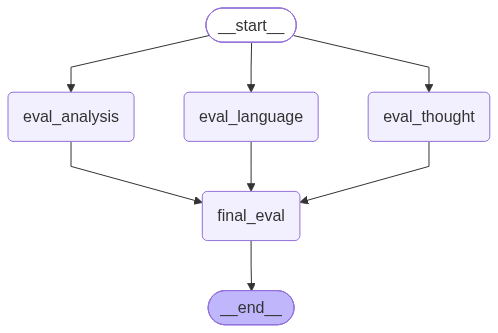

In [17]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

essay:str
    language_feedback:str
    depth_feedback:str
    clarity_feedback:str
    overall_feedback:str

    invidual_score:Annotated[List[int],operator.add]

In [18]:
# -------------------------------------------------------------
# STEP 6: Execute Graph with User Input
# -------------------------------------------------------------
if __name__ == "__main__":
    # Option A: Get essay input from terminal prompt
    user_essay = input("Enter or paste the essay to evaluate:\n\n")

    # Construct initial state with default empty values for optional fields
    initial_state = {
        "essay": user_essay,
        "language_feedback": "",
        "depth_feedback": "",
        "clarity_feedback": "",
        "overall_feedback": "",
        "individual_score": [],
        "average_score": 0.0,
    }

    print("\nEvaluating essay across parallel nodes... Please wait.\n")
    
    # Run the compiled graph
    final_output = app.invoke(initial_state)

    # Display results
    print("=" * 50)
    print("EVALUATION RESULTS")
    print("=" * 50)
    print(f"\nIndividual Aspect Scores: {final_output['individual_score']}")
    print(f"Overall Average Score: {final_output['average_score']:.2f} / 10\n")
    print("-" * 50)
    print("DETAILED ASPECT FEEDBACKS")
    print("-" * 50)
    print(f"\n[Language Quality]\n{final_output['language_feedback']}\n")
    print(f"\n[Depth of Analysis]\n{final_output['depth_feedback']}\n")
    print(f"\n[Clarity of Thought]\n{final_output['clarity_feedback']}\n")
    print("-" * 50)
    print("OVERALL SUMMARY REPORT")
    print("-" * 50)
    print(f"\n{final_output['overall_feedback']}\n")


Evaluating essay across parallel nodes... Please wait.



KeyError: 'essay'

In [20]:
import os
import operator
from typing import TypedDict, Annotated, List
from pydantic import BaseModel, Field
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import StateGraph, START, END

# -------------------------------------------------------------
# 1. Initialize LLMs & Structured Output
# -------------------------------------------------------------
# Raw LLM for generating text summaries
llm_raw = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", temperature=0)

# Pydantic schema for enforcing structured JSON responses
class EvaluationSchema(BaseModel):
    feedback: str = Field(description="Detailed textual feedback for the specific aspect.")
    score: int = Field(description="Score between 0 and 10", ge=0, le=10)

# Bound LLM that returns instances of EvaluationSchema
structured_llm = llm_raw.with_structured_output(EvaluationSchema)


# -------------------------------------------------------------
# 2. Define Shared Graph State
# -------------------------------------------------------------
class UPSCstate(TypedDict):
    essay: str
    language_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str
    # Annotated with operator.add so parallel outputs append scores to a single list
    individual_scores: Annotated[List[int], operator.add]
    average_score: float


# -------------------------------------------------------------
# 3. Define Parallel Evaluation Nodes
# -------------------------------------------------------------
def evaluate_language(state: UPSCstate) -> dict:
    prompt = f"Evaluate the LANGUAGE quality of the following essay:\n\n{state['essay']}"
    res: EvaluationSchema = structured_llm.invoke(prompt)
    return {
        "language_feedback": res.feedback,
        "individual_scores": [res.score]  # Must be passed inside a list [res.score]
    }

def evaluate_analysis(state: UPSCstate) -> dict:
    prompt = f"Evaluate the DEPTH OF ANALYSIS of the following essay:\n\n{state['essay']}"
    res: EvaluationSchema = structured_llm.invoke(prompt)
    return {
        "analysis_feedback": res.feedback, # Key matches state['analysis_feedback']
        "individual_scores": [res.score]
    }

def evaluate_thought(state: UPSCstate) -> dict:
    prompt = f"Evaluate the CLARITY OF THOUGHT of the following essay:\n\n{state['essay']}"
    res: EvaluationSchema = structured_llm.invoke(prompt)
    return {
        "clarity_feedback": res.feedback,
        "individual_scores": [res.score]
    }


# -------------------------------------------------------------
# 4. Define Aggregation Node
# -------------------------------------------------------------
def final_evaluation(state: UPSCstate) -> dict:
    # 1. Summarize textual feedbacks into an overall report
    prompt = (
        f"Combine and summarize the following aspect feedbacks into a coherent report:\n\n"
        f"Language Feedback: {state['language_feedback']}\n"
        f"Analysis Feedback: {state['analysis_feedback']}\n"
        f"Clarity Feedback: {state['clarity_feedback']}"
    )
    summary_res = llm_raw.invoke(prompt)
    
    # 2. Compute the average score from collected parallel score entries
    scores = state["individual_scores"]
    avg_score = sum(scores) / len(scores) if scores else 0.0
    
    return {
        "overall_feedback": summary_res.content,
        "average_score": avg_score
    }


# -------------------------------------------------------------
# 5. Build and Compile Graph
# -------------------------------------------------------------
builder = StateGraph(UPSCstate)

# Add Nodes
builder.add_node("evaluate_language", evaluate_language)
builder.add_node("evaluate_analysis", evaluate_analysis)
builder.add_node("evaluate_thought", evaluate_thought)
builder.add_node("final_evaluation", final_evaluation)

# Fan-Out Edges (Execute evaluations concurrently)
builder.add_edge(START, "evaluate_language")
builder.add_edge(START, "evaluate_analysis")
builder.add_edge(START, "evaluate_thought")

# Fan-In Edges (Aggregate parallel results into final_evaluation)
builder.add_edge("evaluate_language", "final_evaluation")
builder.add_edge("evaluate_analysis", "final_evaluation")
builder.add_edge("evaluate_thought", "final_evaluation")

# Final Edge to complete state execution
builder.add_edge("final_evaluation", END)

# Compile runnable app
app = builder.compile()


# -------------------------------------------------------------
# 6. Execute Workflow
# -------------------------------------------------------------
if __name__ == "__main__":
    sample_essay = """
    Education has historically evolved alongside technological breakthroughs, from the printing press to the internet. 
    Today, Artificial Intelligence (AI) stands as the next major catalyst, reshaping how knowledge is delivered, acquired, and assessed. 
    While AI offers unprecedented opportunities for personalized learning, its integration brings significant ethical and developmental challenges that demand careful navigation.

    On one hand, AI democratizes access to tailored education. Intelligent tutoring systems can adapt to individual learning paces, offering real-time feedback and targeted exercises for students struggling with complex concepts. 
    Furthermore, AI tools reduce administrative burdens for educators, freeing up time for mentorship, interactive discussions, and emotional support. 

    Conversely, over-reliance on automated tools threatens core cognitive development. Critical thinking, analytical reasoning, and creative problem-solving are built through effort, research, and deep engagement. 
    When students rely heavily on AI to summarize texts, solve mathematical equations, or draft essays, they risk diminishing their own intellectual capacity.

    In conclusion, Artificial Intelligence should serve as an empowering assistant rather than a substitute for authentic human learning. 
    The objective of modern education must remain centered on cultivating human curiosity, critical analysis, and ethical reasoning.
    """

    initial_state = {
        "essay": sample_essay,
        "language_feedback": "",
        "analysis_feedback": "",
        "clarity_feedback": "",
        "overall_feedback": "",
        "individual_scores": [],
        "average_score": 0.0,
    }

    print("Executing UPSC essay evaluation graph...\n")
    output = app.invoke(initial_state)

    print("=" * 60)
    print("RESULTS")
    print("=" * 60)
    print(f"Individual Scores: {output['individual_scores']}")
    print(f"Average Score: {output['average_score']:.2f} / 10\n")
    print("-" * 60)
    print("ASPECT FEEDBACKS")
    print("-" * 60)
    print(f"[Language Quality]:\n{output['language_feedback']}\n")
    print(f"[Depth of Analysis]:\n{output['analysis_feedback']}\n")
    print(f"[Clarity of Thought]:\n{output['clarity_feedback']}\n")
    print("-" * 60)
    print("FINAL SUMMARY REPORT")
    print("-" * 60)
    print(f"{output['overall_feedback']}\n")

Executing UPSC essay evaluation graph...



d:\anaconda3\envs\lgenv\Lib\site-packages\langchain_google_genai\chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\anaconda3\envs\lgenv\Lib\site-packages\langchain_google_genai\chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\anaconda3\envs\lgenv\Lib\site-packages\langchain_google_genai\chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\anaconda3\envs\lgenv\Lib\site-packages\langchain_google_genai\chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_

RESULTS
Individual Scores: [7, 10, 10]
Average Score: 9.00 / 10

------------------------------------------------------------
ASPECT FEEDBACKS
------------------------------------------------------------
[Language Quality]:
The essay demonstrates an exceptional command of the English language. The vocabulary is sophisticated and contextually appropriate (e.g., 'catalyst', 'democratizes', 'administrative burdens'). Sentence structures are varied, ranging from simple to complex, and transitions between paragraphs are seamless. Grammar, punctuation, and spelling are virtually flawless, resulting in a formal, academic tone that is highly engaging and easy to follow.

[Depth of Analysis]:
The essay presents a balanced view of AI in education, touching upon both personalized learning benefits and risks to cognitive development. However, the analysis remains somewhat surface-level, relying on broad generalizations rather than deep exploration of specific mechanisms, empirical evidence, or nua

In [22]:
print(output)

{'essay': '\n    Education has historically evolved alongside technological breakthroughs, from the printing press to the internet. \n    Today, Artificial Intelligence (AI) stands as the next major catalyst, reshaping how knowledge is delivered, acquired, and assessed. \n    While AI offers unprecedented opportunities for personalized learning, its integration brings significant ethical and developmental challenges that demand careful navigation.\n\n    On one hand, AI democratizes access to tailored education. Intelligent tutoring systems can adapt to individual learning paces, offering real-time feedback and targeted exercises for students struggling with complex concepts. \n    Furthermore, AI tools reduce administrative burdens for educators, freeing up time for mentorship, interactive discussions, and emotional support. \n\n    Conversely, over-reliance on automated tools threatens core cognitive development. Critical thinking, analytical reasoning, and creative problem-solving a